# 02 · Exploratory Data Analysis
**Duka Electronics · H1 2026 · Phase 4 (Analyse – Python)**

Structure: **univariate → bivariate → segmentation**, each ending with a "so what".
Revenue analysis uses **completed** order lines only (see KPI definitions in notebook 03).

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
DB = ROOT / "data" / "duka.db"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid.axis": "y"})
BRANCH_COLORS = {"Nairobi": "#1F4E79", "Mombasa": "#C0504D", "Nakuru": "#E39B3B",
                 "Eldoret": "#2E8B57", "Kisumu": "#8C8C8C"}
pd.options.display.float_format = "{:,.1f}".format

def save_fig(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150)

In [2]:
with sqlite3.connect(DB) as con:
    df = pd.read_sql("""
        SELECT o.*, p.category, p.product_name, c.county, c.age_band
        FROM orders o
        JOIN products p ON p.product_id = o.product_id
        LEFT JOIN customers c ON c.customer_key = o.customer_key
    """, con, parse_dates=["order_date"])
df["dow"] = df["order_date"].dt.day_name()
done = df[df["is_completed"] == 1].copy()
print(f"{len(df):,} order lines | {len(done):,} completed | {done['net_revenue'].sum()/1e6:,.1f}M KES net revenue")
df.head(3)

15,367 order lines | 14,143 completed | 350.9M KES net revenue


,order_id,order_date,month,quarter,branch,product_id,quantity,unit_price,discount_pct,gross_revenue,...,customer_key,channel,payment_method,order_status,is_completed,category,product_name,county,age_band,dow
0,O014203,2026-06-16,2026-06,Q2,Nakuru,P020,2,"1,802.0",15,"3,604.0",...,Kff730e9037,In-store,Bank Transfer,Completed,1,Accessories,Wireless Mouse,Kisumu,18-24,Tuesday
1,O006009,2026-06-07,2026-06,Q2,Nairobi,P017,1,811.0,0,811.0,...,K2d0a7dbea5,In-store,M-Pesa,Completed,1,Accessories,USB-C Cable,Nairobi,35-44,Sunday
2,O001035,2026-05-14,2026-05,Q2,Mombasa,P017,2,797.0,0,"1,594.0",...,K3a0b083e10,In-store,M-Pesa,Completed,1,Accessories,USB-C Cable,Nakuru,25-34,Thursday


## 1. Univariate analysis

In [3]:
num = done[["quantity", "unit_price", "discount_pct", "net_revenue"]]
desc = num.describe(percentiles=[.5, .9, .99]).T
desc["skew"] = num.skew()
desc

,count,mean,std,min,50%,90%,99%,max,skew
quantity,"14,143.0",1.4,0.8,1.0,1.0,3.0,4.0,4.0,1.8
unit_price,"14,143.0","21,289.2","35,237.0",769.0,"4,823.0","88,383.4","136,195.3","140,641.0",2.1
discount_pct,"14,143.0",3.2,4.6,0.0,0.0,10.0,15.0,15.0,1.2
net_revenue,"14,143.0","24,812.4","43,808.0",655.4,"6,600.0","86,377.4","188,895.5","413,856.0",3.3


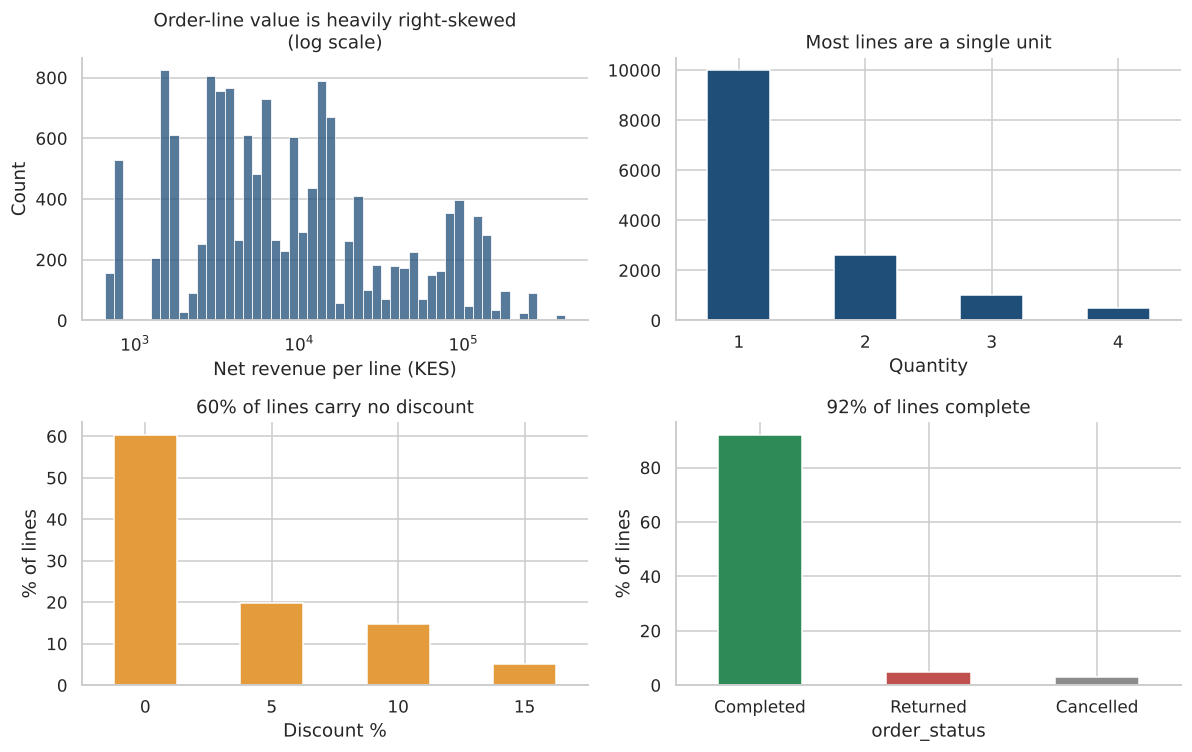

Median line value 6,600 KES vs mean 24,812 KES -> use medians for 'typical' order value.


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(done["net_revenue"], bins=50, log_scale=True, color="#1F4E79", ax=ax[0, 0])
ax[0, 0].set_title("Order-line value is heavily right-skewed\n(log scale)"); ax[0, 0].set_xlabel("Net revenue per line (KES)")
done["quantity"].value_counts().sort_index().plot.bar(color="#1F4E79", ax=ax[0, 1])
ax[0, 1].set_title("Most lines are a single unit"); ax[0, 1].set_xlabel("Quantity"); ax[0, 1].tick_params(axis="x", rotation=0)
done["discount_pct"].value_counts(normalize=True).sort_index().mul(100).plot.bar(color="#E39B3B", ax=ax[1, 0])
ax[1, 0].set_title("60% of lines carry no discount"); ax[1, 0].set_xlabel("Discount %"); ax[1, 0].set_ylabel("% of lines"); ax[1, 0].tick_params(axis="x", rotation=0)
df["order_status"].value_counts(normalize=True).mul(100).plot.bar(color=["#2E8B57", "#C0504D", "#8C8C8C"], ax=ax[1, 1])
ax[1, 1].set_title("92% of lines complete"); ax[1, 1].set_ylabel("% of lines"); ax[1, 1].tick_params(axis="x", rotation=0)
plt.tight_layout(); save_fig(fig, "02_univariate.png"); plt.show()
print(f"Median line value {done.net_revenue.median():,.0f} KES vs mean {done.net_revenue.mean():,.0f} KES -> use medians for 'typical' order value.")

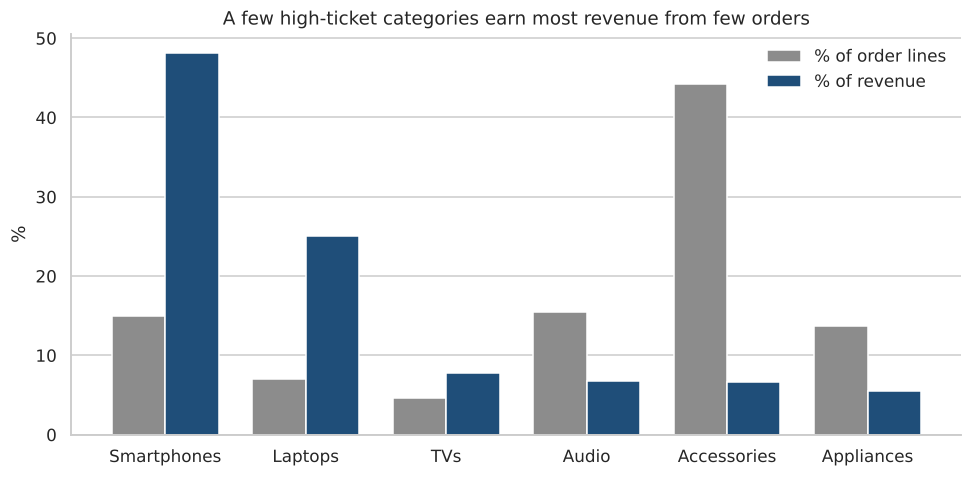

,lines,revenue,pct_lines,pct_revenue
category,,,,
Smartphones,2120,"169,002,936.3",15.0,48.2
Laptops,989,"88,104,130.0",7.0,25.1
TVs,651,"27,240,806.0",4.6,7.8
Audio,2192,"23,776,868.9",15.5,6.8
Accessories,6252,"23,303,843.4",44.2,6.6
Appliances,1939,"19,493,686.2",13.7,5.6


In [5]:
cat = done.groupby("category").agg(lines=("order_id", "count"), revenue=("net_revenue", "sum"))
cat["pct_lines"] = 100 * cat["lines"] / cat["lines"].sum()
cat["pct_revenue"] = 100 * cat["revenue"] / cat["revenue"].sum()
cat = cat.sort_values("pct_revenue", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(cat)); w = 0.38
ax.bar(x - w/2, cat["pct_lines"], w, label="% of order lines", color="#8C8C8C")
ax.bar(x + w/2, cat["pct_revenue"], w, label="% of revenue", color="#1F4E79")
ax.set_xticks(x); ax.set_xticklabels(cat.index); ax.set_ylabel("%"); ax.legend(frameon=False)
ax.set_title("A few high-ticket categories earn most revenue from few orders")
plt.tight_layout(); save_fig(fig, "02_category_mix.png"); plt.show()
cat.round(1)

**So what (univariate):** values are skewed, so we report medians and use non-parametric tests. Revenue is concentrated in smartphones and laptops – investigate by branch next.

## 2. Bivariate analysis

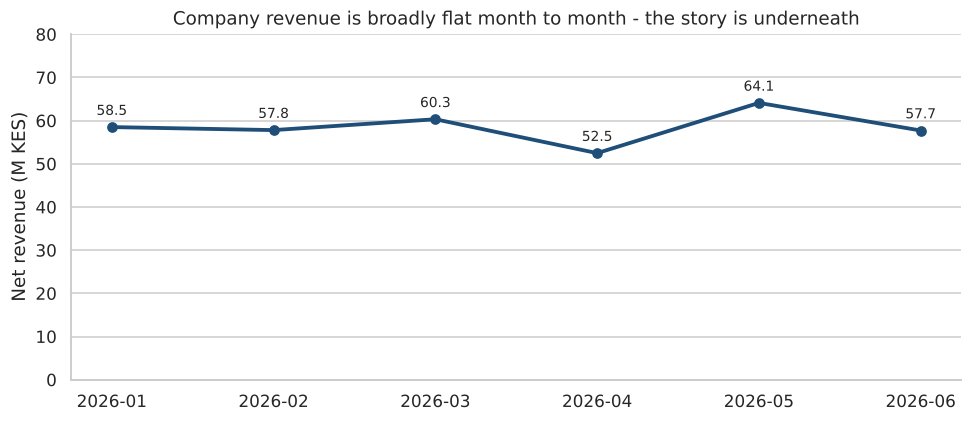

In [6]:
monthly = done.groupby("month")["net_revenue"].sum() / 1e6
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="#1F4E79", lw=2.5)
for x_, y_ in zip(monthly.index, monthly.values):
    ax.annotate(f"{y_:.1f}", (x_, y_), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_ylabel("Net revenue (M KES)"); ax.set_ylim(0, monthly.max() * 1.25)
ax.set_title("Company revenue is broadly flat month to month - the story is underneath")
plt.tight_layout(); save_fig(fig, "02_monthly_total.png"); plt.show()

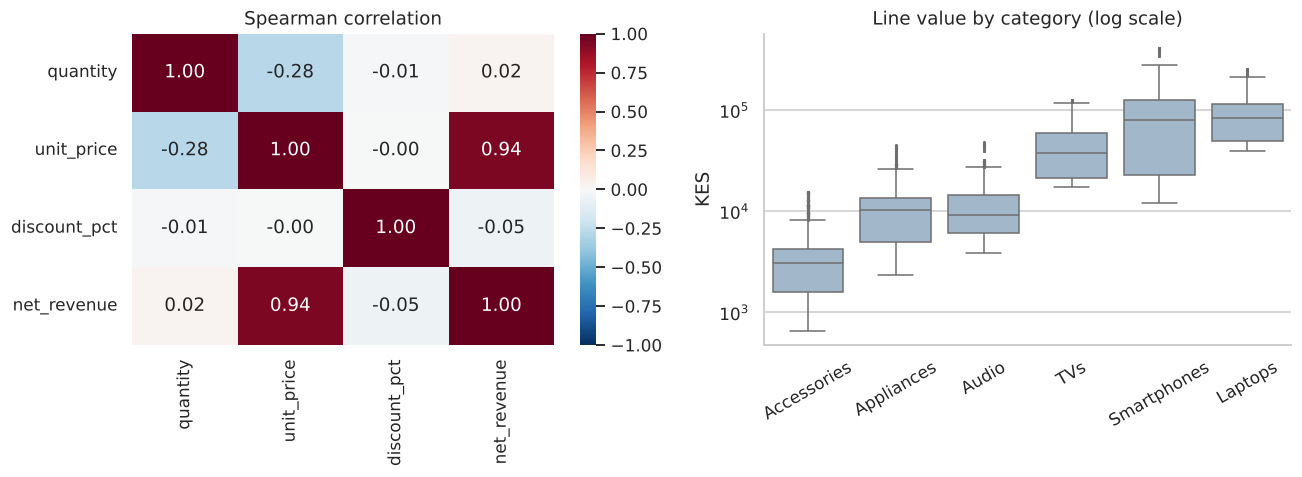

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
corr = done[["quantity", "unit_price", "discount_pct", "net_revenue"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Spearman correlation")
order = ["Accessories", "Appliances", "Audio", "TVs", "Smartphones", "Laptops"]
sns.boxplot(data=done, x="category", y="net_revenue", order=order, color="#9DB7D0", fliersize=1, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_title("Line value by category (log scale)"); ax[1].set_xlabel(""); ax[1].set_ylabel("KES")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig(fig, "02_bivariate.png"); plt.show()

In [8]:
disc = done.groupby("discount_pct").agg(lines=("order_id", "count"), median_value=("net_revenue", "median"),
                                         avg_qty=("quantity", "mean"))
dow = done.groupby("dow")["net_revenue"].sum().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
display(disc.round(2))
print("Share of revenue by weekday (%):"); display((100 * dow / dow.sum()).round(1).to_frame("pct_revenue").T)

,lines,median_value,avg_qty
discount_pct,,,
0,8534,"6,620.0",1.4
5,2796,"7,015.8",1.4
10,2100,"6,688.8",1.4
15,713,"5,513.9",1.4


Share of revenue by weekday (%):


dow,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
pct_revenue,13.7,13.1,12.6,12.8,15.9,16.1,15.9


**So what (bivariate):** discounts show almost no link with quantity or order value, so discounting does not appear to drive bigger baskets. Fri–Sun carry the heaviest trade.

## 3. Segmentation

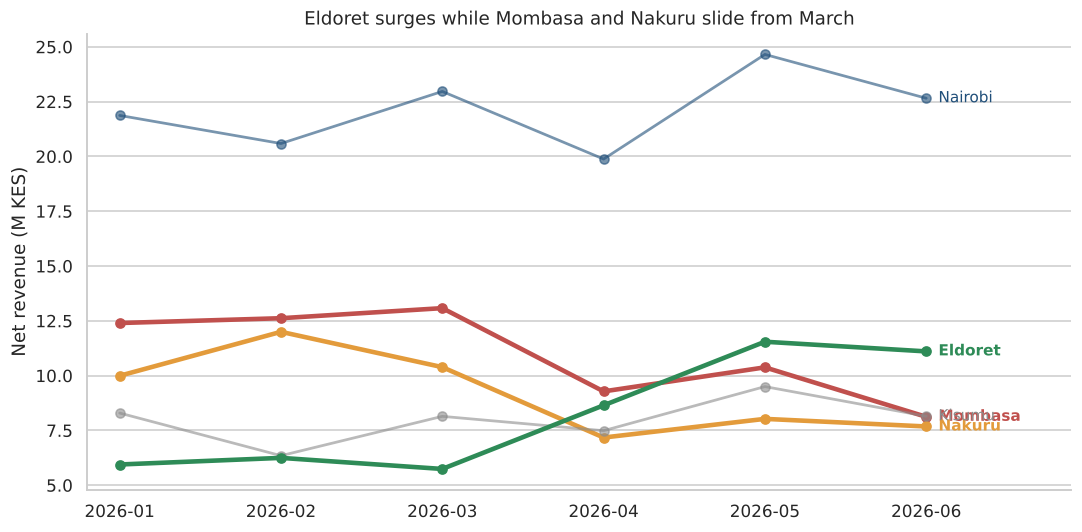

In [9]:
bm = done.pivot_table(index="month", columns="branch", values="net_revenue", aggfunc="sum") / 1e6
order_b = ["Nairobi", "Mombasa", "Nakuru", "Kisumu", "Eldoret"]
fig, ax = plt.subplots(figsize=(10, 5))
for b in order_b:
    hl = b in ("Eldoret", "Mombasa", "Nakuru")
    ax.plot(bm.index, bm[b], marker="o", lw=3 if hl else 1.8, color=BRANCH_COLORS[b], alpha=1 if hl else .6, label=b)
    ax.annotate(b, (bm.index[-1], bm[b].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center",
                color=BRANCH_COLORS[b], fontsize=10, fontweight="bold" if hl else "normal")
ax.set_xlim(-0.2, 5.9); ax.set_ylabel("Net revenue (M KES)")
ax.set_title("Eldoret surges while Mombasa and Nakuru slide from March")
ax.legend().remove(); plt.tight_layout(); save_fig(fig, "02_branch_trend.png"); plt.show()

In [10]:
bq = done.pivot_table(index="branch", columns="quarter", values="net_revenue", aggfunc="sum")
bq["growth_pct"] = 100 * (bq["Q2"] / bq["Q1"] - 1)
bq["share_of_h1_pct"] = 100 * (bq["Q1"] + bq["Q2"]) / (bq["Q1"] + bq["Q2"]).sum()
bq.loc[order_b].round(1)

quarter,Q1,Q2,growth_pct,share_of_h1_pct
branch,,,,
Nairobi,"65,425,883.0","67,190,802.6",2.7,37.8
Mombasa,"38,099,873.4","27,781,336.2",-27.1,18.8
Nakuru,"32,380,567.0","22,885,513.4",-29.3,15.7
Kisumu,"22,785,237.6","25,137,332.2",10.3,13.7
Eldoret,"17,937,846.0","31,297,879.2",74.5,14.0


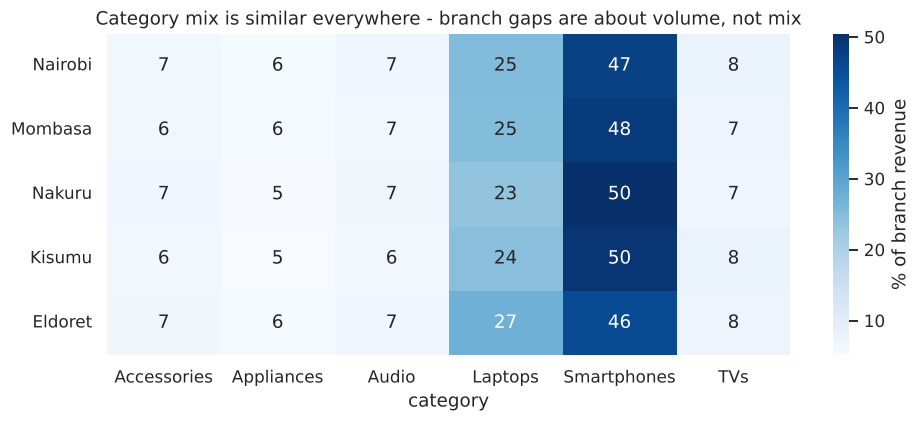

In [11]:
bc = done.pivot_table(index="branch", columns="category", values="net_revenue", aggfunc="sum")
bc_share = bc.div(bc.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(bc_share.loc[order_b], annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of branch revenue"}, ax=ax)
ax.set_title("Category mix is similar everywhere - branch gaps are about volume, not mix"); ax.set_ylabel("")
plt.tight_layout(); save_fig(fig, "02_branch_category_mix.png"); plt.show()

In [12]:
ch = done[done["channel"] != "Unknown"].pivot_table(index="branch", columns="channel", values="net_revenue", aggfunc="sum")
ch = ch.div(ch.sum(axis=1), axis=0) * 100
print("Online share of revenue by branch (%):"); display(ch["Online"].loc[order_b].round(1).to_frame().T)

known = done[done["customer_key"] != "UNKNOWN"]
seg = known.groupby("age_band").agg(customers=("customer_key", "nunique"), revenue=("net_revenue", "sum"))
seg["rev_per_customer"] = seg["revenue"] / seg["customers"]
display(seg.round(0))

cust_rev = known.groupby("customer_key")["net_revenue"].sum().sort_values(ascending=False)
top20 = cust_rev.head(int(len(cust_rev) * 0.2)).sum() / cust_rev.sum()
freq = known.groupby("customer_key").size()
print(f"Top 20% of customers = {top20:.0%} of known-customer revenue (Pareto check)")
print(f"Repeat customers (2+ completed lines): {(freq >= 2).mean():.0%}")

Online share of revenue by branch (%):


branch,Nairobi,Mombasa,Nakuru,Kisumu,Eldoret
Online,26.8,28.3,30.2,25.5,28.6


,customers,revenue,rev_per_customer
age_band,,,
18-24,523,"60,328,272.0","115,350.0"
25-34,935,"105,394,245.0","112,721.0"
35-44,865,"101,535,807.0","117,382.0"
45-54,385,"44,697,362.0","116,097.0"
55+,99,"12,227,797.0","123,513.0"
Unknown,161,"19,488,240.0","121,045.0"


Top 20% of customers = 50% of known-customer revenue (Pareto check)
Repeat customers (2+ completed lines): 96%


## Summary of EDA findings
1. **Distribution:** order values are right-skewed (median ≪ mean) → use medians and non-parametric tests.
2. **Concentration:** smartphones and laptops are ~22% of order lines but roughly three-quarters of revenue.
3. **Branch divergence:** Eldoret accelerates from April; Mombasa and Nakuru fall from April while Nairobi/Kisumu stay stable.
4. **Not a mix problem:** category mix and customer profile look alike across branches, so the divergence is a **volume** issue.
5. **Discounts:** no visible relationship with basket size.

These findings set up the SQL, KPIs and hypothesis tests in notebook 03.